# Interconnect: predicción de la baja de clientes (churn)

Interconnect quiere detectar con anticipación a los clientes que se darán de baja para ofrecerles promociones y planes especiales. Es un problema de **clasificación binaria**: ¿el cliente se dará de baja pronto? (`churn` = 1 / 0).

**Métrica principal:** AUC-ROC en test (meta ≥ 0.88). **Secundaria:** Recall, porque un falso negativo (un cliente que se va y el modelo no lo detecta) es ingreso perdido.

## Etapa 1: Plan de trabajo

1. **Unión y nulos.** `contract` LEFT JOIN `personal`, `internet` y `phone` por `customerID`. Un NaN después de la unión significa que el cliente no tiene ese servicio, no que falte el dato. Se rellena con `"No internet"` o `"No phone"` y no se elimina ninguna fila.
2. **Target.** `churn = 1` si `EndDate` es una fecha y `0` si es `"No"`.
3. **Preprocesamiento por variable.**
   - `BeginDate`/`EndDate` se convierten en `tenure_days`. Para los clientes activos se usa la fecha de corte, que se verifica en el EDA. Después se eliminan las fechas para evitar fugas de información.
   - `TotalCharges` es texto: se convierte a número y los vacíos se rellenan con 0.
   - Features nuevas: `has_internet`, `has_phone` y `n_services`.
   - Categóricas: One-Hot para la Regresión Logística, con las numéricas escaladas; OrdinalEncoder para Random Forest; categóricas nativas para LightGBM.
4. **Modelos.** Split estratificado 60/20/20 (train/validación/test).
   - Baseline sin balanceo: Regresión Logística, Random Forest y LightGBM.
   - Optimización: balanceo de clases (`class_weight` / `is_unbalance`) más `RandomizedSearchCV` con CV estratificada de 5 folds y `scoring="roc_auc"`.
   - Se elige el umbral en validación para alcanzar un Recall de alrededor de 0.80.
   - El modelo final se reentrena con train + validación y se evalúa **una sola vez** en test.

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from lightgbm import LGBMClassifier
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 12345

In [2]:
# Funciones de carga, unión y features (las mismas de src/data.py y src/features.py del repositorio,
# incluidas aquí para que el notebook funcione como un único archivo en la plataforma).
from pathlib import Path

PLATFORM_DIR = Path("/datasets/final_provider")
LOCAL_DIR = Path("final_provider")
TABLES = ("contract", "personal", "internet", "phone")
ADDON_COLS = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
INTERNET_COLS = ["InternetService", *ADDON_COLS]
DROP_COLS = ["customerID", "BeginDate", "EndDate"]


def resolve_data_dir(platform_dir=PLATFORM_DIR, local_dir=LOCAL_DIR):
    """Usa la ruta de la plataforma si existe; si no, la carpeta local del proyecto."""
    return Path(platform_dir) if Path(platform_dir).exists() else Path(local_dir)


def load_raw(data_dir):
    """Lee los cuatro CSV y los devuelve en un diccionario por nombre de tabla."""
    return {name: pd.read_csv(Path(data_dir) / f"{name}.csv") for name in TABLES}


def merge_tables(raw):
    """contract LEFT JOIN personal, internet, phone por customerID."""
    for name in TABLES:
        if raw[name]["customerID"].duplicated().any():
            raise ValueError(f"customerID duplicado en la tabla '{name}'")
    contract = raw["contract"]
    df = contract
    for name in TABLES[1:]:
        df = df.merge(raw[name], on="customerID", how="left")
    if len(df) != len(contract):
        raise ValueError("La unión cambió el número de filas de contract")
    return df


def fill_missing_services(df):
    """NaN tras la unión = el cliente no tiene ese servicio."""
    out = df.copy()
    out[INTERNET_COLS] = out[INTERNET_COLS].fillna("No internet")
    out["MultipleLines"] = out["MultipleLines"].fillna("No phone")
    return out


def add_target(df):
    """churn = 1 si EndDate es una fecha, 0 si es 'No'."""
    out = df.copy()
    if out["EndDate"].isna().any():
        raise ValueError("EndDate tiene valores vacíos: no se puede definir el target")
    out["churn"] = (out["EndDate"] != "No").astype(int)
    return out


def add_tenure(df, cutoff):
    """Días de permanencia; los clientes activos se miden hasta la fecha de corte."""
    out = df.copy()
    begin = pd.to_datetime(out["BeginDate"])
    end = pd.to_datetime(out["EndDate"].mask(out["EndDate"] == "No"))
    end = end.fillna(pd.Timestamp(cutoff))
    if (end < begin).any():
        raise ValueError("Hay contratos que terminan antes de empezar: revisa la fecha de corte")
    out["tenure_days"] = (end - begin).dt.days.astype(int)
    return out


def clean_total_charges(df):
    """TotalCharges vacío = cliente que ingresó en la fecha de corte y aún no paga: 0."""
    out = df.copy()
    out["TotalCharges"] = pd.to_numeric(out["TotalCharges"], errors="coerce").fillna(0.0)
    return out


def add_engineered(df):
    """Indicadores de servicio y número total de servicios contratados."""
    out = df.copy()
    out["has_internet"] = (out["InternetService"] != "No internet").astype(int)
    out["has_phone"] = (out["MultipleLines"] != "No phone").astype(int)
    out["n_services"] = (
        (out[ADDON_COLS] == "Yes").sum(axis=1) + out["has_internet"] + out["has_phone"]
    ).astype(int)
    return out


def build_features(df, cutoff):
    """Aplica toda la preparación y quita ID y fechas (para evitar fugas)."""
    out = fill_missing_services(df)
    out = add_target(out)
    out = add_tenure(out, cutoff)
    out = clean_total_charges(out)
    out = add_engineered(out)
    return out.drop(columns=DROP_COLS)

## Etapa 2.1: Análisis exploratorio

In [3]:
data_dir = resolve_data_dir()
raw = load_raw(data_dir)
print("Datos desde:", data_dir)
for name, table in raw.items():
    print(f"\n=== {name}: {table.shape[0]} filas, {table.shape[1]} columnas, "
          f"customerID duplicados: {table['customerID'].duplicated().sum()}, "
          f"filas duplicadas: {table.duplicated().sum()}")
    table.info()
    display(table.head(3))

Datos desde: final_provider

=== contract: 7043 filas, 8 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   BeginDate         7043 non-null   str    
 2   EndDate           7043 non-null   str    
 3   Type              7043 non-null   str    
 4   PaperlessBilling  7043 non-null   str    
 5   PaymentMethod     7043 non-null   str    
 6   MonthlyCharges    7043 non-null   float64
 7   TotalCharges      7043 non-null   str    
dtypes: float64(1), str(7)
memory usage: 440.3 KB


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,1889.5
2,3668-QPYBK,2019-10-01,2019-12-01 00:00:00,Month-to-month,Yes,Mailed check,53.85,108.15



=== personal: 7043 filas, 5 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     7043 non-null   str  
 1   gender         7043 non-null   str  
 2   SeniorCitizen  7043 non-null   int64
 3   Partner        7043 non-null   str  
 4   Dependents     7043 non-null   str  
dtypes: int64(1), str(4)
memory usage: 275.2 KB


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No



=== internet: 5517 filas, 8 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 5517 entries, 0 to 5516
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   customerID        5517 non-null   str  
 1   InternetService   5517 non-null   str  
 2   OnlineSecurity    5517 non-null   str  
 3   OnlineBackup      5517 non-null   str  
 4   DeviceProtection  5517 non-null   str  
 5   TechSupport       5517 non-null   str  
 6   StreamingTV       5517 non-null   str  
 7   StreamingMovies   5517 non-null   str  
dtypes: str(8)
memory usage: 344.9 KB


,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No



=== phone: 6361 filas, 2 columnas, customerID duplicados: 0, filas duplicadas: 0
<class 'pandas.DataFrame'>
RangeIndex: 6361 entries, 0 to 6360
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerID     6361 non-null   str  
 1   MultipleLines  6361 non-null   str  
dtypes: str(2)
memory usage: 99.5 KB


,customerID,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No


In [4]:
contract = raw["contract"]
begin_max = pd.to_datetime(contract["BeginDate"]).max()
end_max = pd.to_datetime(contract.loc[contract["EndDate"] != "No", "EndDate"]).max()
print("Último BeginDate:", begin_max.date(), "| Último EndDate:", end_max.date())
print("\nDistribución de EndDate entre los clientes que se fueron:")
print(contract.loc[contract["EndDate"] != "No", "EndDate"].value_counts().sort_index())
CUTOFF = "2020-02-01"
assert begin_max == pd.Timestamp(CUTOFF), "La fecha de corte no coincide con los datos"
assert end_max < pd.Timestamp(CUTOFF), "Hay bajas posteriores a la fecha de corte"

Último BeginDate: 2020-02-01 | Último EndDate: 2020-01-01

Distribución de EndDate entre los clientes que se fueron:
EndDate
2019-10-01 00:00:00    458
2019-11-01 00:00:00    485
2019-12-01 00:00:00    466
2020-01-01 00:00:00    460
Name: count, dtype: int64


In [5]:
total_num = pd.to_numeric(contract["TotalCharges"], errors="coerce")
blank = contract[total_num.isna()]
print(f"TotalCharges no numérico: {len(blank)} filas")
display(blank[["customerID", "BeginDate", "EndDate", "MonthlyCharges", "TotalCharges"]])

TotalCharges no numérico: 11 filas


,customerID,BeginDate,EndDate,MonthlyCharges,TotalCharges
488,4472-LVYGI,2020-02-01,No,52.55,
753,3115-CZMZD,2020-02-01,No,20.25,
936,5709-LVOEQ,2020-02-01,No,80.85,
1082,4367-NUYAO,2020-02-01,No,25.75,
1340,1371-DWPAZ,2020-02-01,No,56.05,
3331,7644-OMVMY,2020-02-01,No,19.85,
3826,3213-VVOLG,2020-02-01,No,25.35,
4380,2520-SGTTA,2020-02-01,No,20.00,
5218,2923-ARZLG,2020-02-01,No,19.70,
6670,4075-WKNIU,2020-02-01,No,73.35,


Todos los `TotalCharges` en blanco son de clientes con `BeginDate` igual a la fecha de corte (2020-02-01): acaban de contratar y todavía no se les ha facturado. Por eso se rellenan con **0**, que es el monto real acumulado. Usar `MonthlyCharges` supondría un pago que aún no ocurrió.

In [6]:
merged = merge_tables(raw)
print("Filas tras la unión:", len(merged))
print("\nNulos por columna tras la unión (= servicio no contratado):")
print(merged.isna().sum()[lambda s: s > 0])

Filas tras la unión: 7043

Nulos por columna tras la unión (= servicio no contratado):
InternetService     1526
OnlineSecurity      1526
OnlineBackup        1526
DeviceProtection    1526
TechSupport         1526
StreamingTV         1526
StreamingMovies     1526
MultipleLines        682
dtype: int64


In [7]:
df = build_features(merged, CUTOFF)
df.info()
print("\nBalance de clases:")
print(df["churn"].value_counts().to_frame("clientes").assign(proporción=df["churn"].value_counts(normalize=True).round(3)))

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Type              7043 non-null   str    
 1   PaperlessBilling  7043 non-null   str    
 2   PaymentMethod     7043 non-null   str    
 3   MonthlyCharges    7043 non-null   float64
 4   TotalCharges      7043 non-null   float64
 5   gender            7043 non-null   str    
 6   SeniorCitizen     7043 non-null   int64  
 7   Partner           7043 non-null   str    
 8   Dependents        7043 non-null   str    
 9   InternetService   7043 non-null   str    
 10  OnlineSecurity    7043 non-null   str    
 11  OnlineBackup      7043 non-null   str    
 12  DeviceProtection  7043 non-null   str    
 13  TechSupport       7043 non-null   str    
 14  StreamingTV       7043 non-null   str    
 15  StreamingMovies   7043 non-null   str    
 16  MultipleLines     7043 non-null   str    
 17  churn 

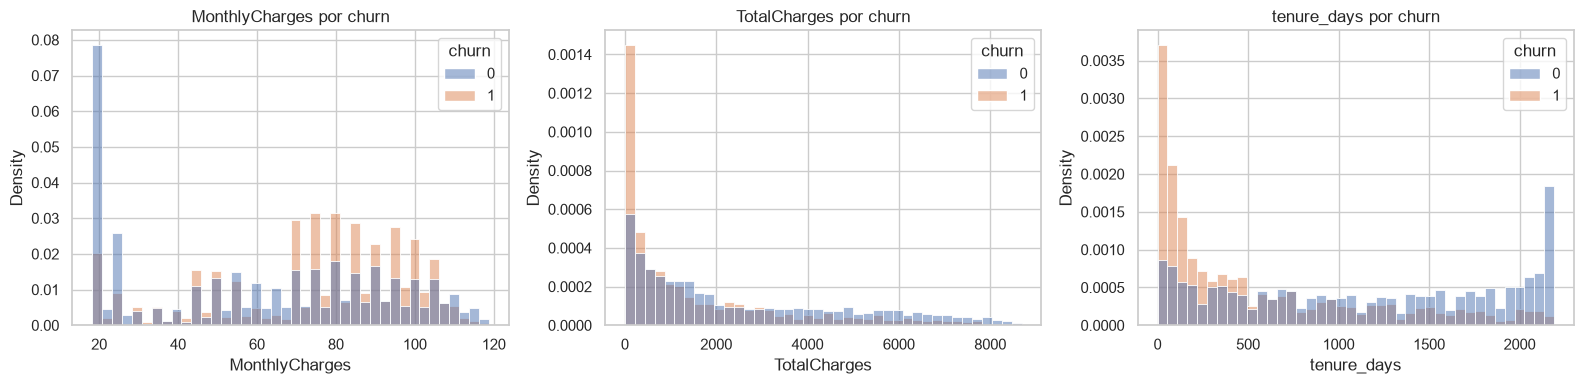

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["MonthlyCharges", "TotalCharges", "tenure_days"]):
    sns.histplot(data=df, x=col, hue="churn", stat="density", common_norm=False, bins=40, ax=ax)
    ax.set_title(f"{col} por churn")
plt.tight_layout()
plt.show()

In [9]:
print("Mediana por churn:")
display(df.groupby("churn")[["tenure_days", "MonthlyCharges"]].median())
churned = df.loc[df["churn"] == 1, "tenure_days"]
print(f"Bajas en los primeros 180 días: {(churned <= 180).mean():.1%}")
print(f"Bajas en el primer año (≤ 365 días): {(churned <= 365).mean():.1%}")

Mediana por churn:


,tenure_days,MonthlyCharges
churn,,
0,1157.0,64.425
1,304.0,79.650


Bajas en los primeros 180 días: 39.8%
Bajas en el primer año (≤ 365 días): 55.5%


Tasa de churn por Type:
Type
Two year          0.028
One year          0.113
Month-to-month    0.427

Tasa de churn por InternetService:
InternetService
No internet    0.074
DSL            0.190
Fiber optic    0.419

Tasa de churn por PaymentMethod:
PaymentMethod
Credit card (automatic)      0.152
Bank transfer (automatic)    0.167
Mailed check                 0.191
Electronic check             0.453



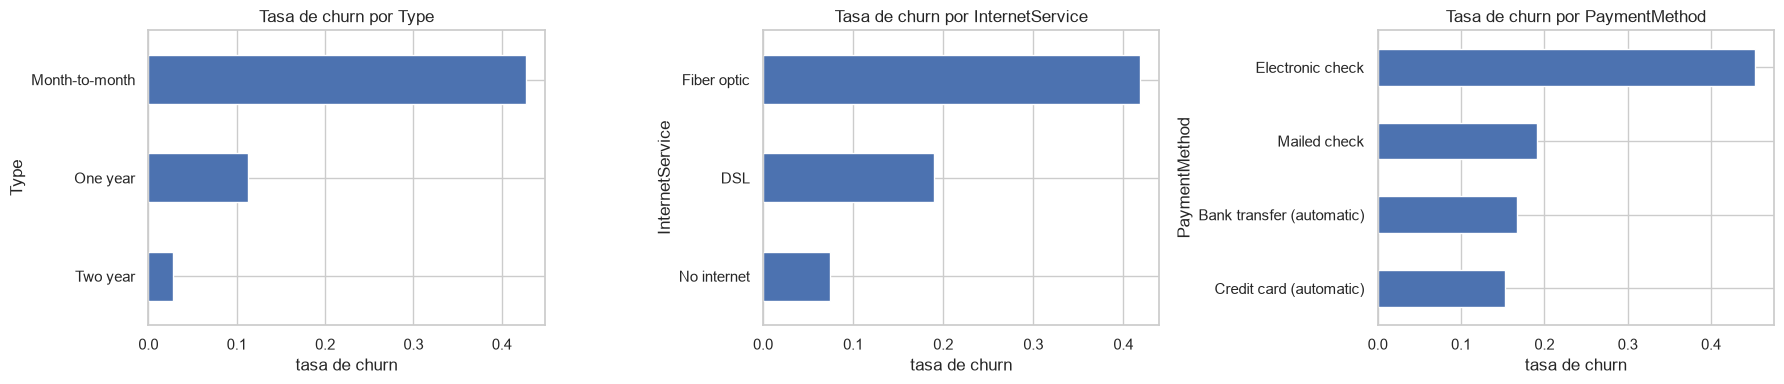

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["Type", "InternetService", "PaymentMethod"]):
    rates = df.groupby(col)["churn"].mean().sort_values()
    print(f"Tasa de churn por {col}:")
    print(rates.round(3).to_string())
    print()
    rates.plot.barh(ax=ax)
    ax.set_title(f"Tasa de churn por {col}")
    ax.set_xlabel("tasa de churn")
plt.tight_layout()
plt.show()

In [11]:
ratio = df["TotalCharges"] / df["MonthlyCharges"]
print("Correlación entre TotalCharges/MonthlyCharges y tenure_days:",
      round(np.corrcoef(ratio, df["tenure_days"])[0, 1], 4))

Correlación entre TotalCharges/MonthlyCharges y tenure_days: 0.9989


### Conclusiones del EDA

- **Desbalance moderado:** el 26.5% de los clientes se dio de baja (1869 de 7043). El split estratificado conservará esa proporción en train, validación y test.
- **Tipo de contrato:** es uno de los factores más claros. Los contratos mes a mes tienen una tasa de churn cercana al 43%, contra 11% en los de un año y 3% en los de dos años.
- **Servicio de internet y pago:** la fibra óptica (≈42%, contra ≈19% en DSL y ≈7% sin internet) y el cheque electrónico (≈45%) concentran las bajas. Los demás métodos de pago (cheque por correo y los dos automáticos) están entre 15% y 19%.
- **Permanencia:** la mediana de `tenure_days` es de 304 días en los clientes que se van, contra 1157 en los que se quedan, y más de la mitad de las bajas ocurre en el primer año. Los que se van también pagan cargos mensuales más altos (mediana de 79.65 contra 64.43).
- **Fechas:** todas las bajas ocurren entre 2019-10-01 y 2020-01-01, y el último `BeginDate` es 2020-02-01, que confirma la fecha de corte. Por eso las fechas no se usan como features (solo `tenure_days`).
- **Razón `TotalCharges / MonthlyCharges`:** su correlación con `tenure_days` es 0.9989 (≥ 0.95), así que **no se agrega**: sería redundante.

**Nota sobre la Regresión Logística:** `has_internet` y `has_phone` repiten la información de las categorías `"No internet"` / `"No phone"` del One-Hot. La colinealidad no impide el ajuste gracias a la regularización L2, pero los coeficientes de esas columnas no se interpretan por separado.

## Etapa 2.2: Preprocesamiento y división de los datos

In [12]:
X = df.drop(columns="churn")
y = df["churn"]
X_trval, X_test, y_trval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)
X_train, X_valid, y_train, y_valid = train_test_split(
    X_trval, y_trval, test_size=0.25, stratify=y_trval, random_state=RANDOM_STATE)
for name, part, target in [("train", X_train, y_train), ("valid", X_valid, y_valid), ("test", X_test, y_test)]:
    print(f"{name}: {part.shape}, churn = {target.mean():.3f}")

train: (4225, 21), churn = 0.265
valid: (1409, 21), churn = 0.265
test: (1409, 21), churn = 0.265


In [13]:
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_cols = X.select_dtypes(include="number").columns.tolist()
print("Categóricas:", cat_cols)
print("Numéricas:", num_cols)

# Regresión logística: One-Hot (sin orden artificial) + escalado (coeficientes comparables y convergencia).
# drop="if_binary" deja una sola columna en las variables Sí/No y evita duplicar información.
ohe_prep = ColumnTransformer([
    ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols),
])
# Random Forest: los árboles no necesitan escalado y OrdinalEncoder evita multiplicar columnas.
ord_prep = ColumnTransformer([
    ("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), cat_cols),
    ("num", "passthrough", num_cols),
])
# LightGBM: categóricas nativas. Las categorías se fijan solo con train.
cat_dtypes = {c: pd.CategoricalDtype(sorted(X_train[c].unique())) for c in cat_cols}
X_train_lgb, X_valid_lgb, X_test_lgb = (part.astype(cat_dtypes) for part in (X_train, X_valid, X_test))

Categóricas: ['Type', 'PaperlessBilling', 'PaymentMethod', 'gender', 'Partner', 'Dependents', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'MultipleLines']
Numéricas: ['MonthlyCharges', 'TotalCharges', 'SeniorCitizen', 'tenure_days', 'has_internet', 'has_phone', 'n_services']


In [14]:
def evaluate(model, X, y, threshold=0.5):
    """AUC-ROC (con probabilidades) y Recall/Precisión con el umbral dado."""
    proba = model.predict_proba(X)[:, 1]
    pred = (proba >= threshold).astype(int)
    return {
        "AUC-ROC": roc_auc_score(y, proba),
        "Recall": recall_score(y, pred),
        "Precisión": precision_score(y, pred, zero_division=0),
    }

## Etapa 2.3: Modelos baseline (sin balanceo)

Tres modelos con parámetros por defecto, entrenados en train y evaluados en validación con umbral 0.5.

In [15]:
def make_logreg(**kw):
    return Pipeline([("prep", clone(ohe_prep)),
                     ("model", LogisticRegression(max_iter=2000, random_state=RANDOM_STATE, **kw))])

def make_rf(n_jobs=-1, **kw):
    return Pipeline([("prep", clone(ord_prep)),
                     ("model", RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=n_jobs, **kw))])

def make_lgbm(n_jobs=-1, **kw):
    return LGBMClassifier(random_state=RANDOM_STATE, n_jobs=n_jobs, verbose=-1, **kw)

DATA = {
    "LogisticRegression": (X_train, X_valid, X_test),
    "RandomForest": (X_train, X_valid, X_test),
    "LightGBM": (X_train_lgb, X_valid_lgb, X_test_lgb),
}
candidates, rows = {}, []
for name, model in {"LogisticRegression": make_logreg(), "RandomForest": make_rf(), "LightGBM": make_lgbm()}.items():
    X_tr, X_va, _ = DATA[name]
    model.fit(X_tr, y_train)
    candidates[(name, "baseline")] = model
    rows.append({"modelo": name, "etapa": "baseline", "AUC-ROC CV": np.nan, **evaluate(model, X_va, y_valid)})
results = pd.DataFrame(rows)
results.round(4)

,modelo,etapa,AUC-ROC CV,AUC-ROC,Recall,Precisión
0,LogisticRegression,baseline,NaN,0.8570,0.5401,0.6801
1,RandomForest,baseline,NaN,0.8511,0.5401,0.7214
2,LightGBM,baseline,NaN,0.9013,0.6230,0.7767


## Etapa 2.4: Balanceo de clases + búsqueda de hiperparámetros

El churn es la clase minoritaria (cerca de 26%), así que se aplica **ponderación de clases** (`class_weight="balanced"`; en LightGBM, `is_unbalance=True`). Así se penalizan más los errores sobre los clientes que se van, sin duplicar ni descartar filas. La búsqueda usa `RandomizedSearchCV` con CV estratificada de 5 folds sobre train y `scoring="roc_auc"`.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search_spaces = {
    "LogisticRegression": (
        make_logreg(class_weight="balanced"),
        {"model__C": loguniform(1e-3, 1e2)},
        30,
    ),
    "RandomForest": (
        make_rf(n_jobs=1, class_weight="balanced"),
        {"model__n_estimators": randint(200, 801),
         "model__max_depth": [None, 6, 8, 10, 12, 16, 20],
         "model__min_samples_leaf": randint(1, 21),
         "model__max_features": ["sqrt", "log2", 0.5]},
        30,
    ),
    "LightGBM": (
        make_lgbm(n_jobs=1, is_unbalance=True, subsample_freq=1),
        {"n_estimators": randint(200, 1501),
         "learning_rate": loguniform(0.01, 0.2),
         "num_leaves": randint(8, 65),
         "min_child_samples": randint(5, 61),
         "subsample": uniform(0.6, 0.4),
         "colsample_bytree": uniform(0.6, 0.4),
         "reg_lambda": loguniform(1e-3, 10)},
        50,
    ),
}
searches = {}
for name, (estimator, params, n_iter) in search_spaces.items():
    X_tr, X_va, _ = DATA[name]
    search = RandomizedSearchCV(estimator, params, n_iter=n_iter, scoring="roc_auc",
                                cv=cv, random_state=RANDOM_STATE, n_jobs=-1)
    search.fit(X_tr, y_train)
    searches[name] = search
    candidates[(name, "optimizado")] = search.best_estimator_
    rows.append({"modelo": name, "etapa": "optimizado", "AUC-ROC CV": search.best_score_,
                 **evaluate(search.best_estimator_, X_va, y_valid)})
    print(f"{name}: mejores parámetros {search.best_params_}")
results = pd.DataFrame(rows)

LogisticRegression: mejores parámetros {'model__C': np.float64(0.2177684881685945)}


RandomForest: mejores parámetros {'model__max_depth': 8, 'model__max_features': 0.5, 'model__min_samples_leaf': 1, 'model__n_estimators': 445}


LightGBM: mejores parámetros {'colsample_bytree': np.float64(0.7044505159946781), 'learning_rate': np.float64(0.019727397180640458), 'min_child_samples': 13, 'n_estimators': 1216, 'num_leaves': 15, 'reg_lambda': np.float64(0.17657775897730493), 'subsample': np.float64(0.9269166147562844)}


In [17]:
pd.set_option("display.width", 200)
(results.pivot_table(index="modelo", columns="etapa", dropna=False,
                     values=["AUC-ROC CV", "AUC-ROC", "Recall", "Precisión"])
        .reindex(columns=["AUC-ROC CV", "AUC-ROC", "Recall", "Precisión"], level=0)
        .round(4))

AUC-ROC CV             AUC-ROC              Recall            Precisión           
etapa                baseline optimizado baseline optimizado baseline optimizado  baseline optimizado
modelo                                                                                               
LightGBM                  NaN     0.8922   0.9013     0.9075   0.6230     0.7781    0.7767     0.6705
LogisticRegression        NaN     0.8427   0.8570     0.8564   0.5401     0.8102    0.6801     0.5450
RandomForest              NaN     0.8580   0.8511     0.8755   0.5401     0.7968    0.7214     0.5960

### Comparación baseline vs. optimizado

- **LightGBM es el mejor modelo** en las dos etapas: AUC-ROC en validación de 0.9013 (baseline) y 0.9075 (optimizado), por encima de la meta de 0.88 (que se medirá en test). Random Forest optimizado queda en 0.8755 y la Regresión Logística en ≈0.857.
- **El balanceo sube mucho el Recall** con umbral 0.5: LightGBM pasa de 0.6230 a 0.7781, Random Forest de 0.5401 a 0.7968 y la Regresión Logística de 0.5401 a 0.8102. A cambio, la precisión baja (LightGBM: de 0.7767 a 0.6705), porque se marcan más clientes como "en riesgo".
- **Random Forest es el que más gana** con la etapa optimizada (+0.024 de AUC). Como esa etapa combina balanceo y búsqueda de hiperparámetros, la mejora no se puede atribuir solo a uno de los dos. En la Regresión Logística el AUC casi no cambia (0.8570 → 0.8564): el balanceo desplaza sobre todo el intercepto (el umbral efectivo) y apenas altera el orden de las probabilidades, y el nuevo `C` tampoco lo cambia de forma relevante.
- **La CV coincide con validación:** el AUC de CV queda entre 0.014 y 0.018 por debajo del de validación en los tres modelos. Esa diferencia es esperable, porque cada fold entrena con el 80% de train y la validación es un solo split de 1409 filas. Como es pequeña y consistente, no sugiere sobreajuste ni fuga de datos.

## Selección del modelo y del umbral

Se elige el candidato con mayor AUC-ROC en validación. Después, con su curva de precisión-recall en validación, se busca el umbral más alto que todavía da un Recall ≥ 0.80. Así se detecta a la mayoría de los clientes que se van y se contacta al menor número posible de clientes que se quedan.

Modelo elegido: ('LightGBM', 'optimizado')
Umbral elegido: 0.470


Validación con ese umbral: {'AUC-ROC': 0.9075, 'Recall': 0.8021, 'Precisión': 0.6522}


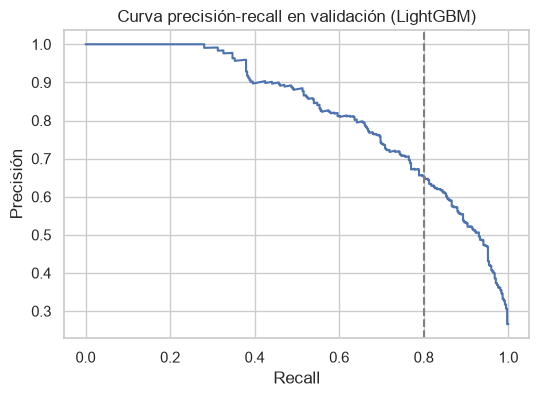

In [18]:
best_row = results.loc[results["AUC-ROC"].idxmax()]
best_key = (best_row["modelo"], best_row["etapa"])
best_model = candidates[best_key]
X_tr, X_va, X_te = DATA[best_key[0]]
print("Modelo elegido:", best_key)

TARGET_RECALL = 0.80
proba_valid = best_model.predict_proba(X_va)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_valid, proba_valid)
threshold = thresholds[recall[:-1] >= TARGET_RECALL].max()
print(f"Umbral elegido: {threshold:.3f}")
print("Validación con ese umbral:", {k: round(v, 4) for k, v in evaluate(best_model, X_va, y_valid, threshold).items()})

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(recall, precision)
ax.axvline(TARGET_RECALL, ls="--", c="gray")
ax.set_xlabel("Recall")
ax.set_ylabel("Precisión")
ax.set_title(f"Curva precisión-recall en validación ({best_key[0]})")
plt.show()

## Prueba final en test

El modelo elegido se reentrena con train + validación, con los mismos hiperparámetros y el mismo umbral, y se evalúa **una única vez** en el conjunto de prueba.

Se asume que el umbral elegido con el modelo entrenado solo en train se transfiere al modelo reentrenado (con un 33% más de datos las probabilidades pueden desplazarse un poco). El Recall obtenido en test permite comprobarlo.

Resultados en TEST: {'AUC-ROC': 0.9036, 'Recall': 0.8075, 'Precisión': 0.6331}
Umbral: 0.470
Clientes en test: 1409 | VP (bajas detectadas): 302 | FN (bajas no detectadas): 72 | FP (contactados sin necesidad): 175 | VN: 860


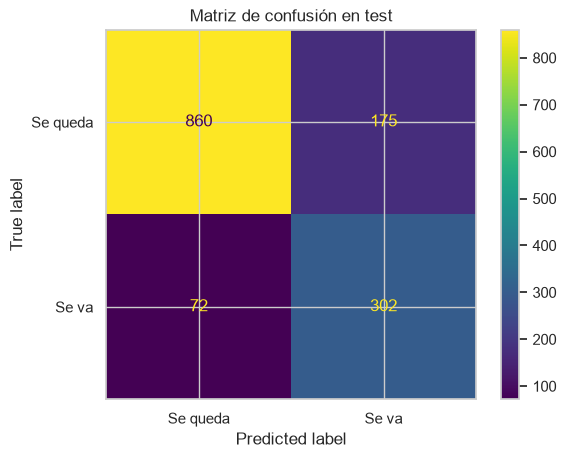

In [19]:
final_model = clone(best_model)
final_model.fit(pd.concat([X_tr, X_va]), pd.concat([y_train, y_valid]))
test_metrics = evaluate(final_model, X_te, y_test, threshold)
print("Resultados en TEST:", {k: round(v, 4) for k, v in test_metrics.items()})
print(f"Umbral: {threshold:.3f}")

pred_test = (final_model.predict_proba(X_te)[:, 1] >= threshold).astype(int)
tn, fp, fn, tp = pd.crosstab(y_test, pred_test).reindex(index=[0, 1], columns=[0, 1], fill_value=0).to_numpy().ravel()
print(f"Clientes en test: {len(y_test)} | VP (bajas detectadas): {tp} | FN (bajas no detectadas): {fn} | "
      f"FP (contactados sin necesidad): {fp} | VN: {tn}")
ConfusionMatrixDisplay.from_predictions(y_test, pred_test, display_labels=["Se queda", "Se va"])
plt.title("Matriz de confusión en test")
plt.show()

Top 10 features por importancia:
tenure_days         5963
TotalCharges        3257
MonthlyCharges      3192
Type                 583
n_services           452
gender               415
MultipleLines        363
PaperlessBilling     328
PaymentMethod        277
OnlineSecurity       264
dtype: int32


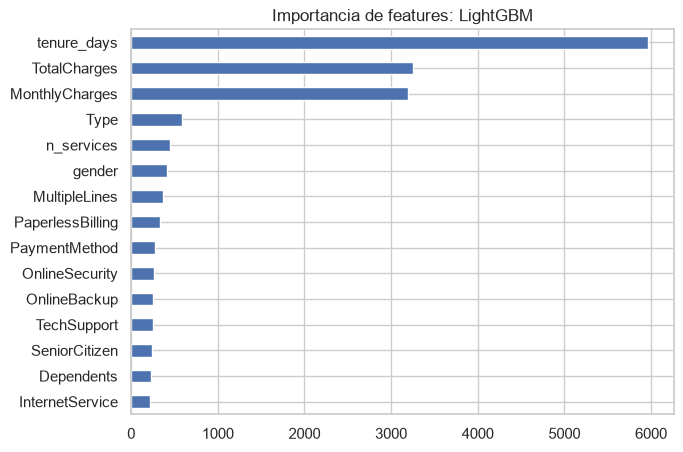

In [20]:
if isinstance(final_model, Pipeline):
    estimator = final_model.named_steps["model"]
    names = final_model.named_steps["prep"].get_feature_names_out()
else:
    estimator, names = final_model, X_te.columns
values = (estimator.feature_importances_ if hasattr(estimator, "feature_importances_")
          else np.abs(estimator.coef_[0]))
importance = pd.Series(values, index=names).sort_values()
print("Top 10 features por importancia:")
print(importance.tail(10)[::-1])
importance.tail(15).plot.barh(figsize=(7, 5))
plt.title(f"Importancia de features: {best_key[0]}")
plt.show()

## Etapa 3: Informe para negocio

**Modelo elegido:** LightGBM (optimizado, con `is_unbalance=True` y búsqueda de hiperparámetros). Es el que obtuvo el mayor AUC-ROC en validación (0.9075), frente a 0.8755 de Random Forest optimizado y ≈0.857 de la Regresión Logística, y además su AUC de CV (0.8922) fue el más alto.

**Resultados en test** (datos nunca usados para entrenar ni ajustar):

| Métrica | Valor |
|---|---|
| AUC-ROC | 0.9036 |
| Recall | 0.8075 |
| Precisión | 0.6331 |
| Umbral | 0.470 |

El AUC-ROC en test (0.9036) supera la meta de 0.88 y queda muy cerca del de validación (0.9075), así que el modelo generaliza bien. El Recall en test (0.8075) también se mantiene por encima del objetivo de 0.80 con el que se eligió el umbral.

**¿Qué significa?**
- De cada 100 clientes que realmente se van, el modelo detecta a 81.
- De cada 100 clientes que el modelo marca como "en riesgo", 63 realmente se iban a ir. El resto recibiría una promoción sin necesitarla: es el costo de no perder a los demás.
- En el conjunto de test (1409 clientes): 302 bajas detectadas a tiempo, 72 bajas no detectadas y 175 clientes contactados sin necesidad.
- **Si marketing lo usa hoy:** de cada 477 clientes contactados (los que superan el umbral), 302 son clientes que se iban a ir. Cuántos de ellos se retienen depende de la tasa de éxito de la promoción, que no se mide en estos datos: por ejemplo, *si* la oferta convenciera a 3 de cada 10, se evitarían unas 90 de esas 302 bajas.

**Recomendación de uso:** ejecutar el modelo cada mes sobre los clientes activos y enviar a marketing la lista de clientes por encima del umbral, ordenada por probabilidad. Si la campaña tiene presupuesto limitado, subir el umbral: se contacta a menos gente con más precisión, a cambio de menos Recall. Las cuatro variables que más usa el modelo son la permanencia (`tenure_days`), los cargos (`TotalCharges` y `MonthlyCharges`) y el tipo de contrato, que coinciden con los factores más claros del EDA: los clientes nuevos, con contrato mes a mes y cargos mensuales altos son los de mayor riesgo. Por eso, una oferta de migración a un contrato anual es una **palanca candidata**. Pero el notebook solo muestra asociación, no causalidad (los clientes ya fieles pueden ser los que eligen contratos largos), así que su efecto conviene validarlo con una prueba A/B o un grupo de control antes de generalizarla.

*Nota sobre la importancia:* LightGBM cuenta cuántas veces se usa cada variable para dividir los árboles, lo que favorece a las numéricas continuas. Sirve para identificar las variables principales, pero no indica el sentido del efecto, y el orden fuera de las cuatro primeras (por ejemplo, `gender` en el sexto lugar) no se debe interpretar como relevancia para el negocio.